<a href="https://colab.research.google.com/github/smon2006/E-Commerce_Dynamic_Price_Prediction/blob/main/Project_2_E-Commerce_Dynamic_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: E-Commerce Dynamic Price Prediction</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

### Question 1: Data Loading & Dimensionality Assessment (5 Marks)

Load the 'diamonds' dataset via the OpenML repository to access a standard retail jewelry dataset. Extract it into a Pandas DataFrame and display the first five rows alongside the dataset's overall dimensions.

**Hint:** Utilize the dataset fetching functionality from `sklearn.datasets` referencing the correct string identifier (`name="diamonds"`). Ensure the returned object is formatted as a structured DataFrame.

**Expected Output:** A pandas DataFrame displaying the numerical and categorical features of the retail items, along with a tuple representing the total number of rows and columns.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml

diamonds = fetch_openml(name="diamonds", as_frame=True, parser="auto")
df = diamonds.frame.copy()

print("First five rows:")
display(df.head())
print("\nDataset dimensions (rows, columns):", df.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/datasets/_openml.py:323: UserWarning: Multiple active versions of the dataset matching the name diamonds exist. Versions may be fundamentally different, returning version 1. Available versions:
- version 1, status: active
  url: https://www.openml.org/search?type=data&id=42225
- version 2, status: active
  url: https://www.openml.org/search?type=data&id=43998

  warn(warning_msg)


First five rows:


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75



Dataset dimensions (rows, columns): (53940, 10)


### Question 2: Invalid Data Cleaning & Reasoning (6 Marks)

In physical retail products, spatial dimensions cannot be zero. Identify and remove any rows where the dimension features ('x', 'y', or 'z') have a value of exactly 0. Print the number of rows removed. Additionally, provide a brief analytical justification for why dropping these rows is preferable to imputing them with the feature mean in this specific context. Print your written answer using Python `print()` statements.

**Hint:** Construct a boolean mask to filter out anomalous rows. Calculate the difference in row counts before and after the operation.

**Expected Output:** A printed statement detailing the exact count of anomalous rows dropped, the new shape of the DataFrame, and a printed analytical paragraph justifying the chosen data cleaning strategy.

In [ ]:
rows_before = df.shape[0]

invalid_mask = (df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0)
df = df[~invalid_mask].reset_index(drop=True)

rows_removed = rows_before - df.shape[0]
print(f"Rows before cleaning : {rows_before}")
print(f"Rows removed         : {rows_removed}")
print(f"New shape            : {df.shape}")

print(f"""
Justification: A diamond cannot have a dimension of 0 mm, so these zeros are data errors,
not real values. Mean imputation would give these stones a size that contradicts their
carat weight and distort the size-price relationship. Since only {rows_removed} rows
({rows_removed / rows_before:.3%}) are affected, dropping them loses almost no information.
""")

Rows before cleaning : 53940
Rows removed         : 20
New shape            : (53920, 10)

Justification: A diamond cannot have a dimension of 0 mm, so these zeros are data errors,
not real values. Mean imputation would give these stones a size that contradicts their
carat weight and distort the size-price relationship. Since only 20 rows
(0.037%) are affected, dropping them loses almost no information.



### Question 3: Categorical Feature Encoding (6 Marks)

The dataset contains categorical features ('cut', 'color', 'clarity') that possess a strict ordinal hierarchy. Map these categorical text values into sequential integers representing their quality ranking from lowest to highest. To ensure standardization, use the following strict industry hierarchies (listed from lowest to highest quality):

*   **Cut:** Fair < Good < Very Good < Premium < Ideal
*   **Color:** J < I < H < G < F < E < D
*   **Clarity:** I1 < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < IF

**Hint:** Define explicit mapping dictionaries based on the provided hierarchies and apply them to the respective columns to overwrite the text values.

**Expected Output:** A transformed DataFrame where the specified text-based categorical columns have been replaced entirely by standardized integer scales.

In [ ]:
cut_map     = {"Fair": 1, "Good": 2, "Very Good": 3, "Premium": 4, "Ideal": 5}
color_map   = {"J": 1, "I": 2, "H": 3, "G": 4, "F": 5, "E": 6, "D": 7}
clarity_map = {"I1": 1, "SI2": 2, "SI1": 3, "VS2": 4, "VS1": 5, "VVS2": 6, "VVS1": 7, "IF": 8}

df["cut"]     = df["cut"].astype(str).map(cut_map)
df["color"]   = df["color"].astype(str).map(color_map)
df["clarity"] = df["clarity"].astype(str).map(clarity_map)

assert df[["cut", "color", "clarity"]].isnull().sum().sum() == 0, "Unmapped category found"
df[["cut", "color", "clarity"]] = df[["cut", "color", "clarity"]].astype(int)

display(df.head())
print(df.dtypes)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,5,6,2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,4,6,3,59.8,61.0,326,3.89,3.84,2.31
2,0.23,2,6,5,56.9,65.0,327,4.05,4.07,2.31
3,0.29,4,2,4,62.4,58.0,334,4.20,4.23,2.63
4,0.31,2,1,2,63.3,58.0,335,4.34,4.35,2.75


carat      float64
cut          int64
color        int64
clarity      int64
depth      float64
table      float64
price        int64
x          float64
y          float64
z          float64
dtype: object


### Question 4: Outlier Treatment via IQR (6 Marks)

Extreme pricing anomalies can skew regression models. Implement the Interquartile Range (IQR) method specifically on the target variable ('price') to detect outliers. Remove any rows that fall outside the standard $1.5 \times IQR$ boundary.

**Hint:** Calculate the first and third quartiles of the target variable to establish the IQR, then filter the DataFrame to retain only the observations within the calculated lower and upper bounds.

**Expected Output:** A quantitative summary showing the original row count, the number of outlier rows discarded, and the finalized row count of the cleaned dataset.

In [ ]:
original_rows = df.shape[0]

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)].reset_index(drop=True)

print(f"Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
print(f"Acceptable price range : [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Original row count     : {original_rows}")
print(f"Outlier rows discarded : {original_rows - df.shape[0]}")
print(f"Final row count        : {df.shape[0]}")

Q1 = 949.00, Q3 = 5323.25, IQR = 4374.25
Acceptable price range : [-5612.38, 11884.62]
Original row count     : 53920
Outlier rows discarded : 3532
Final row count        : 50388


### Question 5: Exploratory Data Analysis & Multicollinearity (7 Marks)

Compute and visualize a correlation matrix for the continuous numerical variables in the dataset. Identify which features exhibit strong multicollinearity with one another. Print your written answer using Python `print()` statements detailing your observations and explaining mathematically or structurally why multicollinearity can be problematic for distance-based or linear models.

**Hint:** Utilize standard data visualization libraries to generate a heatmap of the correlation coefficients. Focus your written analysis on predictor variables that share very high correlation scores.

**Expected Output:** A visual heatmap plot displaying correlation values, accompanied by a printed analytical text block discussing the observed multicollinearity and its implications.

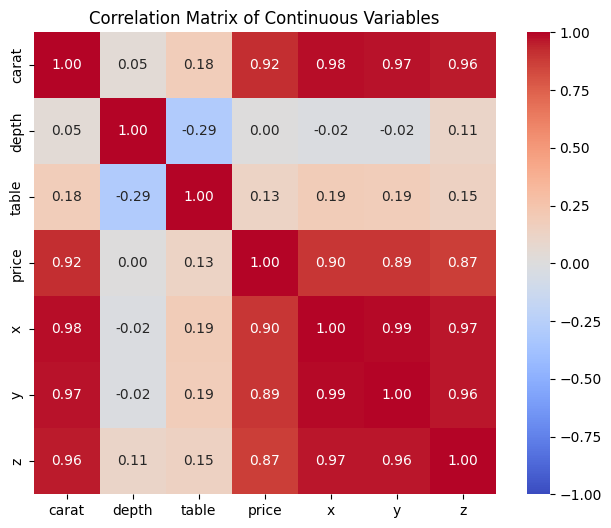

Predictor pairs with |correlation| >= 0.8:
  carat vs x: r = 0.983
  carat vs y: r = 0.974
  carat vs z: r = 0.961
  x vs y: r = 0.991
  x vs z: r = 0.969
  y vs z: r = 0.963

Observations: carat, x, y and z are almost perfectly correlated with each other (and with
price), because they all measure the size of the stone. depth and table are only weakly
correlated with the rest.

Why multicollinearity is a problem:
- Linear models: near-duplicate predictors make X^T X almost singular, so coefficient
  estimates become unstable and hard to interpret.
- Distance-based models (KNN, K-Means): redundant features count the same information
  several times in the Euclidean distance, so 'size' gets over-weighted.



In [ ]:
continuous_cols = ["carat", "depth", "table", "price", "x", "y", "z"]
corr = df[continuous_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Continuous Variables")
plt.show()

predictors = [c for c in continuous_cols if c != "price"]
pairs = []
for i, a in enumerate(predictors):
    for b in predictors[i + 1:]:
        if abs(corr.loc[a, b]) >= 0.8:
            pairs.append((a, b, corr.loc[a, b]))

print("Predictor pairs with |correlation| >= 0.8:")
for a, b, r in pairs:
    print(f"  {a} vs {b}: r = {r:.3f}")

print("""
Observations: carat, x, y and z are almost perfectly correlated with each other (and with
price), because they all measure the size of the stone. depth and table are only weakly
correlated with the rest.

Why multicollinearity is a problem:
- Linear models: near-duplicate predictors make X^T X almost singular, so coefficient
  estimates become unstable and hard to interpret.
- Distance-based models (KNN, K-Means): redundant features count the same information
  several times in the Euclidean distance, so 'size' gets over-weighted.
""")

### Question 6: Data Splitting and Standardization (6 Marks)

Separate the dataset into feature columns (X) and the target variable (y = 'price'). Split these arrays into training and testing sets utilizing an 80/20 ratio. Apply standard scaling to the training features and transform the testing features accordingly. You must explicitly convert the resulting scaled numerical arrays back into Pandas DataFrames to retain the original column names for subsequent feature interpretation.

**Hint:** Ensure the scaler is fitted solely on the training data to prevent data leakage. Reconstruct the DataFrames using the scaled arrays and the column attributes from the original feature set.

**Expected Output:** Four pandas DataFrames or NumPy arrays representing the scaled predictors (as DataFrames with column headers) and their target values for both the training and testing phases.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=["price"])
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),      columns=X.columns, index=X_test.index)

print("X_train_scaled:", X_train_scaled.shape, "| X_test_scaled:", X_test_scaled.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
display(X_train_scaled.head())

X_train_scaled: (40310, 9) | X_test_scaled: (10078, 9)
y_train: (40310,) | y_test: (10078,)


,carat,cut,color,clarity,depth,table,x,y,z
12883,1.679918,0.081169,-2.037087,0.556931,-1.231495,2.060452,1.665172,1.630136,1.392894
9113,0.744323,0.081169,0.326529,-1.262102,-0.035521,1.161743,0.780866,0.837132,0.776423
12140,0.718334,-1.704318,1.508337,-0.049413,0.245884,2.959162,0.800964,0.766866,0.792230
30392,-1.126868,0.973912,-0.855279,0.556931,0.456939,-1.534385,-1.359557,-1.331080,-1.262674
24128,-1.048901,0.973912,-0.855279,1.163276,0.034830,-1.085031,-1.208823,-1.170471,-1.152025


### Question 7: Baseline Linear Regression (5 Marks)

Train a baseline Linear Regression model on the scaled training dataset. Once trained, generate an array of price predictions using the scaled test dataset.

**Hint:** Instantiate the standard linear modeling class, fit it using the training predictors and targets, and apply the prediction method to the test predictors.

**Expected Output:** A one-dimensional array containing continuous numerical values representing the model's estimated retail prices for the test set.

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
print("Shape of predictions:", y_pred_lr.shape)
print("First 10 predicted prices:", np.round(y_pred_lr[:10], 2))

Shape of predictions: (10078,)
First 10 predicted prices: [4312.55 4481.89 2144.17  117.38 1138.57  330.55  799.2  5954.12 3984.95
 6682.34]


### Question 8: Baseline Model Evaluation & Interpretation (6 Marks)

Quantify the performance of your baseline Linear Regression model by calculating three specific metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R-squared score ($R^2$). Print your written answer using Python `print()` statements to explain what the calculated RMSE value implies about the average prediction error in the specific context of retail jewelry pricing.

**Hint:** Utilize standard regression metric functions. Consider the units of the target variable when interpreting the RMSE value.

**Expected Output:** A formatted text block printing the calculated values for MAE, RMSE, and $R^2$, followed by a qualitative paragraph interpreting the real-world meaning of the RMSE magnitude.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_lr  = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr   = r2_score(y_test, y_pred_lr)

print("Baseline Linear Regression")
print(f"  MAE  : {mae_lr:,.2f}")
print(f"  RMSE : {rmse_lr:,.2f}")
print(f"  R^2  : {r2_lr:.4f}")

print(f"""
Interpretation: RMSE is in the same units as price (US dollars). The model's estimates are
typically off by about ${rmse_lr:,.0f}, which is {rmse_lr / y_test.mean():.1%} of the average test
price (${y_test.mean():,.0f}). RMSE is larger than MAE (${mae_lr:,.0f}) because squaring
penalises large errors more, so a few big mispricings are pulling it up. This is a sizeable
error for cheaper stones, which suggests a purely linear model is too simple.
""")

Baseline Linear Regression
  MAE  : 599.44
  RMSE : 874.36
  R^2  : 0.8987

Interpretation: RMSE is in the same units as price (US dollars). The model's estimates are
typically off by about $874, which is 27.7% of the average test
price ($3,161). RMSE is larger than MAE ($599) because squaring
penalises large errors more, so a few big mispricings are pulling it up. This is a sizeable
error for cheaper stones, which suggests a purely linear model is too simple.



### Question 9: Custom Regression Metric - Asymmetric Pricing Error (8 Marks)

In retail pricing, underpricing a product immediately costs the company profit margins, whereas overpricing reduces conversion probability. Write a custom python function that calculates an Asymmetric Mean Absolute Error. This metric must apply a 2x penalty weight to underpriced predictions (prediction < actual) compared to overpriced predictions (prediction >= actual). Compute this score for your baseline model.

**Hint:** Calculate the raw error difference for each test instance. Implement conditional logic (or vectorized equivalent) to double the absolute error when the predicted value falls short of the true value, then return the overall mean.

**Expected Output:** A single float value representing the custom business penalty score for the baseline linear model.

In [ ]:
def asymmetric_mae(y_true, y_pred, under_penalty=2.0):
    """Mean absolute error where under-pricing (prediction < actual) is penalised 2x."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    abs_error = np.abs(y_true - y_pred)
    weights = np.where(y_pred < y_true, under_penalty, 1.0)
    return float(np.mean(weights * abs_error))

asym_lr = asymmetric_mae(y_test, y_pred_lr)
print(f"Asymmetric MAE (baseline Linear Regression): {asym_lr:,.4f}")

Asymmetric MAE (baseline Linear Regression): 903.6296


### Question 10: Ridge Regression & Hyperparameter Tuning (8 Marks)

To address the potential multicollinearity identified during your EDA, implement Ridge Regression. Utilize a Grid Search with cross-validation to find the optimal regularization parameter (alpha) from a predefined sequence of values (e.g., 0.1, 1.0, 10.0, 100.0). Train the optimal model and calculate the $R^2$ score on the test set. Print your written answer using Python `print()` statements to explain the mechanism by which Ridge regularization mitigates the effects of correlated features.

**Hint:** Construct a parameter grid dictionary and apply cross-validated grid search methodology. Analyze how the L2 penalty alters the magnitude of model coefficients.

**Expected Output:** The optimal alpha parameter found during tuning, the resulting $R^2$ score on the test data, and a printed analytical explanation of the regularization process.

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

param_grid = {"alpha": [0.1, 1.0, 10.0, 100.0]}
ridge_cv = GridSearchCV(Ridge(), param_grid, cv=5, scoring="r2")
ridge_cv.fit(X_train_scaled, y_train)

best_ridge = ridge_cv.best_estimator_
y_pred_ridge = best_ridge.predict(X_test_scaled)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Optimal alpha        :", ridge_cv.best_params_["alpha"])
print(f"Best CV R^2          : {ridge_cv.best_score_:.4f}")
print(f"Test R^2 (Ridge)     : {r2_ridge:.4f}   (baseline Linear Regression: {r2_lr:.4f})")

print("""
How Ridge helps with correlated features: Ridge adds an L2 penalty (alpha * sum of squared
coefficients) to the loss. This keeps X^T X well-conditioned and shrinks the coefficients,
so when carat, x, y and z carry the same information, the weight is spread across them
in small, stable amounts instead of huge opposite-signed ones. It trades a little bias
for a large reduction in variance.
""")

Optimal alpha        : 100.0
Best CV R^2          : 0.9007
Test R^2 (Ridge)     : 0.8986   (baseline Linear Regression: 0.8987)

How Ridge helps with correlated features: Ridge adds an L2 penalty (alpha * sum of squared
coefficients) to the loss. This keeps X^T X well-conditioned and shrinks the coefficients,
so when carat, x, y and z carry the same information, the weight is spread across them
in small, stable amounts instead of huge opposite-signed ones. It trades a little bias
for a large reduction in variance.



### Question 11: Non-Linear Ensemble Modeling (7 Marks)

To capture complex non-linear relationships in retail pricing, train a Random Forest Regressor on the scaled training dataset. Generate predictions on the test set and evaluate the model using both the standard $R^2$ score and your custom Asymmetric Pricing Error derived previously.

**Hint:** Initialize the ensemble regressor with parameters that balance depth and estimator count to manage execution time. Apply your previously defined custom function to the new predictions.

**Expected Output:** A quantitative printout showing both the $R^2$ metric and the Custom Asymmetric Error, which should conceptually display an improvement over the baseline linear models.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)
r2_rf   = r2_score(y_test, y_pred_rf)
asym_rf = asymmetric_mae(y_test, y_pred_rf)

print(f"Random Forest  R^2                : {r2_rf:.4f}   (Linear Regression: {r2_lr:.4f})")
print(f"Random Forest  Asymmetric MAE     : {asym_rf:,.4f}   (Linear Regression: {asym_lr:,.4f})")

Random Forest  R^2                : 0.9814   (Linear Regression: 0.8987)
Random Forest  Asymmetric MAE     : 307.0001   (Linear Regression: 903.6296)


### Question 12: Feature Importance & Business Inference (8 Marks)

Determine which physical or quality characteristics drive pricing decisions the most. Extract the calculated feature importances from your trained Random Forest model. Combine these values with their corresponding feature names, sort them in descending order, and display the result. Finally, print your written answer using Python `print()` statements to outline the primary business inferences derived from this ranking.

**Hint:** Extract the importance attribute from the ensemble object. Since the scaled data was retained as a DataFrame, map these importance scores to the columns attribute. Formulate analytical reasoning based on the top-ranking features.

**Expected Output:** A sorted tabular structure or series ranking the predictor variables by influence, followed by printed analytical text discussing the real-world implications of the most influential attributes.

In [ ]:
importances = pd.Series(rf.feature_importances_, index=X_train_scaled.columns).sort_values(ascending=False)
importance_df = importances.rename("importance").to_frame()
display(importance_df)

top3 = list(importances.index[:3])
top3_share = importances.iloc[:3].sum()
quality_share = importances[["cut", "color", "clarity"]].sum()

print(f"""
Business inferences:
1. Top 3 features: {top3[0]}, {top3[1]}, {top3[2]} ({top3_share:.1%} of importance), so size is the
   main price driver and pricing should be anchored on it first.
2. cut, color and clarity add only {quality_share:.1%} combined: secondary markups within a size band.
3. depth and table matter very little, so the pricing engine can de-prioritise them.
""")

,importance
y,0.797263
carat,0.080144
clarity,0.072219
color,0.033804
x,0.005844
z,0.004014
depth,0.002641
cut,0.002103
table,0.001969



Business inferences:
1. Top 3 features: y, carat, clarity (95.0% of importance), so size is the
   main price driver and pricing should be anchored on it first.
2. cut, color and clarity add only 10.8% combined: secondary markups within a size band.
3. depth and table matter very little, so the pricing engine can de-prioritise them.



### Question 13: Multi-Layer Perceptron Regression (8 Marks)

Construct and train a Multi-Layer Perceptron (MLP) Regressor to estimate the product prices. Configure the neural network topology to possess exactly two hidden layers, each containing 64 neurons. Evaluate its performance on the test data by calculating the $R^2$ score.

**Hint:** Define the topology using the appropriate hidden layer tuple parameter. Ensure the iteration limit is sufficient to allow weight convergence.

**Expected Output:** The calculated $R^2$ score indicating the predictive capacity of the deep learning architecture on unseen test records.

In [ ]:
from sklearn.neural_network import MLPRegressor

mlp = MLPRegressor(hidden_layer_sizes=(64, 64), max_iter=1000, early_stopping=True,
                   n_iter_no_change=20, random_state=42)
mlp.fit(X_train_scaled, y_train)

y_pred_mlp = mlp.predict(X_test_scaled)
r2_mlp = r2_score(y_test, y_pred_mlp)
print(f"MLP (64, 64) R^2 on test set: {r2_mlp:.4f}")
print("Iterations run:", mlp.n_iter_)

MLP (64, 64) R^2 on test set: 0.9767
Iterations run: 135


### Question 14: MLP Hyperparameter Optimization (8 Marks)

Optimize the neural network by performing a Grid Search with 3-fold cross-validation. Search over two distinct activation functions ('relu', 'tanh') and two learning rate initializations (0.001, 0.01) for a condensed MLP model featuring a single hidden layer of 32 neurons. Output the optimal configuration.

**Hint:** Formulate a dictionary containing the grid search space parameters. Pass this dictionary to the cross-validation search object along with the estimator, and inspect the optimal parameters attribute upon completion.

**Expected Output:** A dictionary or formatted text string displaying the exact combination of activation function and learning rate that yielded the highest cross-validated performance metric.

In [ ]:
mlp_param_grid = {
    "activation": ["relu", "tanh"],
    "learning_rate_init": [0.001, 0.01],
}

mlp_grid = GridSearchCV(
    MLPRegressor(hidden_layer_sizes=(32,), max_iter=1000, early_stopping=True,
                 n_iter_no_change=20, random_state=42),
    mlp_param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1,
)
mlp_grid.fit(X_train_scaled, y_train)

print("Optimal configuration :", mlp_grid.best_params_)
print(f"Best 3-fold CV R^2    : {mlp_grid.best_score_:.4f}")

best_mlp = mlp_grid.best_estimator_
y_pred_best_mlp = best_mlp.predict(X_test_scaled)
print(f"Test R^2 of tuned MLP : {r2_score(y_test, y_pred_best_mlp):.4f}")

Optimal configuration : {'activation': 'tanh', 'learning_rate_init': 0.01}
Best 3-fold CV R^2    : 0.9789
Test R^2 of tuned MLP : 0.9790


### Question 15: Unsupervised Market Segmentation & Pricing Analysis (6 Marks)

Segment the test set inventory into 3 distinct tiers (e.g., budget, mid-range, premium) strictly based on physical weight ('carat') and actual cost ('price'). Extract these two columns from the test set, apply independent scaling, and utilize the K-Means clustering algorithm to assign a tier label to every product. Create a summary DataFrame grouping the instances by cluster label, calculating the Mean Actual Price and the Mean Predicted Price (utilizing predictions from your most accurate model) for each segment.

**Hint:** Isolate the target columns into a temporary structure and scale them before fitting the clustering algorithm. Combine the resulting cluster labels, actual values, and predicted values into a single DataFrame, then apply aggregation functions to compute the group means.

**Expected Output:** A structured summary table indexed by the unsupervised segment labels, allowing an objective comparison between the average real-world price and the algorithm's average estimation for each inventory tier.

In [ ]:
from sklearn.cluster import KMeans

candidates = {
    "Linear Regression": y_pred_lr,
    "Ridge": y_pred_ridge,
    "Random Forest": y_pred_rf,
    "MLP (64,64)": y_pred_mlp,
    "Tuned MLP (32)": y_pred_best_mlp,
}
scores = {name: r2_score(y_test, pred) for name, pred in candidates.items()}
best_name = max(scores, key=scores.get)
y_pred_best = candidates[best_name]
print("Test R^2 by model:", {k: round(v, 4) for k, v in scores.items()})
print("Most accurate model used for the summary:", best_name)

seg = pd.DataFrame({"carat": X_test["carat"].values, "price": y_test.values})
seg_scaled = StandardScaler().fit_transform(seg)

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
seg["cluster"] = kmeans.fit_predict(seg_scaled)
seg["predicted_price"] = y_pred_best

summary = seg.groupby("cluster").agg(
    count=("price", "size"),
    mean_carat=("carat", "mean"),
    mean_actual_price=("price", "mean"),
    mean_predicted_price=("predicted_price", "mean"),
)

order = summary["mean_actual_price"].sort_values().index
tier_names = dict(zip(order, ["Budget", "Mid-range", "Premium"]))
summary.index = summary.index.map(tier_names)
summary = summary.loc[["Budget", "Mid-range", "Premium"]]
summary["difference (pred - actual)"] = summary["mean_predicted_price"] - summary["mean_actual_price"]
display(summary.round(2))

Test R^2 by model: {'Linear Regression': 0.8987, 'Ridge': 0.8986, 'Random Forest': 0.9814, 'MLP (64,64)': 0.9767, 'Tuned MLP (32)': 0.979}
Most accurate model used for the summary: Random Forest


,count,mean_carat,mean_actual_price,mean_predicted_price,difference (pred - actual)
cluster,,,,,
Budget,5518,0.43,1176.83,1186.69,9.86
Mid-range,3272,0.96,4313.42,4345.12,31.71
Premium,1288,1.37,8736.53,8636.03,-100.50
